In [1]:
#Import all necessary libraries
import json
import re
import numpy as np
import pandas as pd
import altair as alt
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
nltk.download("stopwords")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\marti\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

1. As a first step, you must pre-process the documents. In particular, for the text fields (title, 
description) you should:  

● Removing stop words 

● Tokenization 

● Removing punctuation marks 

● Stemming 

● and... anything else you think it's needed (bonus point) 

In [2]:
docs_path = "../../data/fashion_products_dataset.json"

with open(docs_path, "r", encoding="utf-8") as fp:
    data = json.load(fp)

df = pd.DataFrame(data)
print("Total number of products in the corpus: {}".format(len(df)))

Total number of products in the corpus: 28080


In [3]:
df.head()

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,1612987913000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,1612987913000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


In [4]:
#We have collected this code from Practice 1, doing some minor changes and adding the bonus

#This functions takes a string from a focument and returns a normalised list of tokens by lowercasing, removing punctuation, tokenising, dropping, and applying  stemming.

stemmer = PorterStemmer()                
stop_words = set(stopwords.words("english"))
extra_stop_words = set() # bonus

def build_terms(line):
    """
    Preprocess the article text (title + body): removing stop words, stemming,
    transforming in lowercase and return the tokens of the text.

    Argument:
    line -- string (text) to be preprocessed

    Returns:
    line - a list of tokens corresponding to the input text after the preprocessing
    """


    if not isinstance(line, str):                      # missing values (None / NaN)
        return []
    line = line.lower()                                # lowercase
    line = re.sub(r"[^a-z0-9\s]", " ", line)           # remove punctuation marks
    line = line.split()                                # Tokenize the text to get a list of terms
    line = [x for x in line if x not in stop_words and x not in extra_stop_words]
    line = [stemmer.stem(word) for word in line]       #  perform stemming
    return line

In [5]:
text = df.loc[0, "description"]
print("Original:\n{}\n".format(text))
print("Terms:\n{}\n".format(build_terms(text)))
print(build_terms("100% Cotton, Men's T-Shirt!!"), build_terms(""), build_terms(None))

Original:
Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India

Terms:
['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']

['100', 'cotton', 'men', 'shirt'] [] []


In [12]:
#Apply the function build_terms in the fields of title and description
df["title_terms"] = [build_terms(title) for title in df["title"]]
df["description_terms"] = [build_terms(description) for description in df["description"]]
df["details_terms"] = df["product_details"].fillna("").astype(str).apply(build_terms)
df["brand_terms"] = df["brand"].apply(build_terms)
df["seller_terms"] = df["seller"].apply(build_terms)
df["category_terms"] = (
    df["category"].fillna("").astype(str) + " " +
    df["sub_category"].fillna("").astype(str)
).apply(build_terms)

In [13]:
# See how often every token appears and show the 30 most frequent.
title_counts = Counter(t for terms in df["title_terms"] for t in terms)
print(title_counts.most_common(30))

term_counts = Counter(t for terms in df["description_terms"] for t in terms)
print(term_counts.most_common(30))

[('shirt', 15838), ('women', 13146), ('men', 13060), ('neck', 11952), ('solid', 9246), ('round', 8301), ('print', 8123), ('pack', 4839), ('blue', 4378), ('fit', 3923), ('black', 3503), ('casual', 2927), ('slim', 2893), ('polo', 2668), ('collar', 2427), ('multicolor', 2373), ('white', 2175), ('sleev', 2030), ('full', 2011), ('2', 1966), ('grey', 1917), ('regular', 1778), ('cotton', 1656), ('3', 1568), ('sweatshirt', 1343), ('dark', 1340), ('design', 1329), ('self', 1325), ('green', 1298), ('color', 1295)]
[('shirt', 18321), ('cotton', 10139), ('wear', 9353), ('comfort', 8836), ('look', 6413), ('casual', 6034), ('fit', 5831), ('made', 5643), ('fabric', 5516), ('print', 4888), ('women', 4424), ('design', 4301), ('sleev', 4221), ('qualiti', 4087), ('men', 3775), ('wash', 3731), ('day', 3617), ('style', 3275), ('make', 3233), ('100', 3210), ('feel', 3160), ('neck', 2991), ('perfect', 2973), ('soft', 2742), ('great', 2740), ('pair', 2734), ('stylish', 2716), ('keep', 2669), ('polo', 2623), (

2. Take into account that for future queries, the final output must return (when present) the 
following information for each of the selected documents:  
pid, title, description,  brand,  category, sub_category, product_details, seller, out_of_stock, 
selling_price, discount, actual_price, average_rating, url 

In [14]:
output_fields = ["pid", "title", "description", "brand", "category", "sub_category", "product_details", "seller", "out_of_stock", 
"selling_price", "discount", "actual_price", "average_rating", "url"]

4. Consider the fields out_of_stock, selling_price, discount, actual_price, and average_rating. 
Decide how these should be handled during pre-processing to use in further search. Should 
they be indexed as textual terms?

In [15]:
def parse_number(x):
    """
    Change from string to number

    Argument:
    x -- string (or number) to parse

    Returns:
    float, or NaN if no number can be extracted
    """
    #If number doesn't need pre-processing
    if isinstance(x, (int, float)):
        return float(x)

    
    match = re.search(r"\d[\d,]*\.?\d*", str(x)) # scan for the pattern anywhere
    return float(match.group().replace(",", "")) if match else np.nan #convert or fall back to NaN

In [17]:
# calculated how well different product fields match each query
labels = pd.read_csv("../../data/validation_labels.csv")
queries = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
fields = ["title_terms", "description_terms", "details_terms",
          "brand_terms", "seller_terms", "category_terms"]

relevant = labels[labels["labels"] == 1].merge(df, on="pid")

for qid, q in queries.items():
    q_terms = set(build_terms(q))
    rel = relevant[relevant["query_id"] == qid]
    print("Query", qid, sorted(q_terms))
    for f in fields:
        result = rel[f].apply(lambda t: len(q_terms & set(t)) / len(q_terms)).mean()
        print(" ", f, f"{result:.0%}")

Query 1 ['cotton', 'full', 'sleev', 'sweatshirt', 'women']
  title_terms 80%
  description_terms 58%
  details_terms 80%
  brand_terms 0%
  seller_terms 0%
  category_terms 0%
Query 2 ['blue', 'jean', 'men', 'slim']
  title_terms 80%
  description_terms 35%
  details_terms 65%
  brand_terms 0%
  seller_terms 0%
  category_terms 0%


## Exploratory Data Analysis (EDA)

**Dataset summary**

In [18]:
print("Number of products:", len(df)) #how many products we have
print("Number of columns:", len(df.columns)) #number of columns

print("Dataset columns:") #which columns we have in the dataset
print(df.columns.tolist())

print("Missing values per column:") #nulls
print(df.isna().sum().sort_values(ascending=False))

print("Empty descriptions:") #empties
print((df["description"].fillna("").str.strip() == "").sum())

print("Duplicate product IDs:") #duplicates
print(df["pid"].duplicated().sum())

Number of products: 28080
Number of columns: 23
Dataset columns:
['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url', 'title_terms', 'description_terms', 'details_terms', 'brand_terms', 'seller_terms', 'category_terms']
Missing values per column:
_id                  0
actual_price         0
average_rating       0
brand                0
category             0
crawled_at           0
description          0
discount             0
images               0
out_of_stock         0
pid                  0
product_details      0
seller               0
selling_price        0
sub_category         0
title                0
url                  0
title_terms          0
description_terms    0
details_terms        0
brand_terms          0
seller_terms         0
category_terms       0
dtype: int64
Empty descriptions:
11150
Duplicate product IDs:


The dataset contains 28,080 products and 17 original attributes. With the preprocessing, 7 additional columns were created to store textual information, so the final number of columns is 24.

There are no duplicated IDs. Although there are no nulls, we observe that 11,150 products have empty descriptions.

This is relevant because relying only on description of the products would exclude a substancial portion of the dataset. Therefore, product titles and other textual attributes should also be considered during indexing.

**Product distribution**

Category distribution

Number of categories: 4
Products per category:
category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64


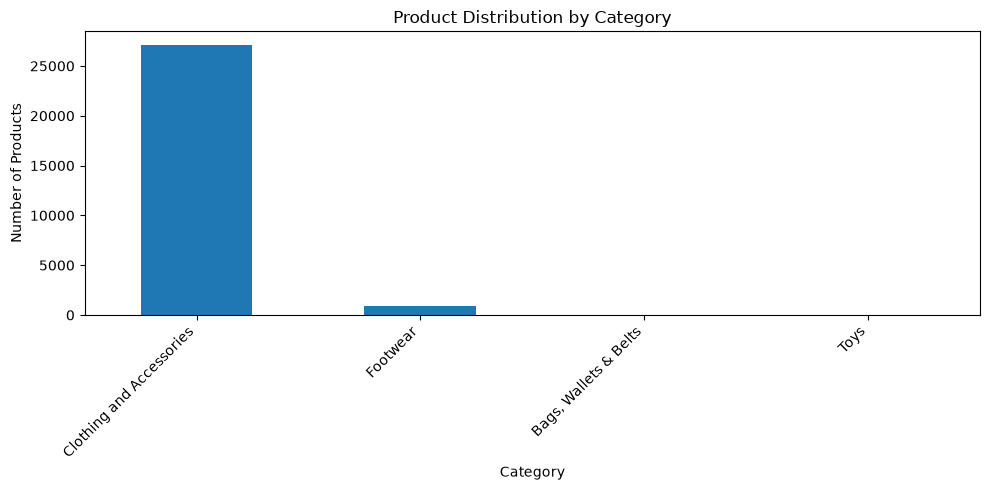

In [19]:
import matplotlib.pyplot as plt

category_counts = df["category"].value_counts() #count by category

print("Number of categories:", df["category"].nunique())
print("Products per category:")
print(category_counts)

plt.figure(figsize=(10, 5))
category_counts.plot(kind="bar")

plt.title("Product Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


The dataset is highly imbalanced across product categories. We can see that CLothing and Accessories category dominates all the dataset with 27118 products, followed by Footwear with only 920 products. The remaining categories represents the other 42 products, 41 for Bags, Wallets & Belts and 1 for toys.

This imbalance is relevant for information retrieval because the search engine will have more products available for queries related with clothing than for the other categories. Therefore, the results and evaluation performance for the retrieval system will differ depending on the categpry of the product.

Subcategory distribution

Number of subcategories: 24
Top 15 subcategories:
sub_category
Topwear                                15310
Bottomwear                              3666
Winter Wear                             2493
Innerwear and Swimwear                  1762
Clothing Accessories                    1742
Kurtas, Ethnic Sets and Bottoms         1180
Men's Footwear                           920
Fabrics                                  534
Sleepwear                                122
Blazers, Waistcoats and Suits            103
Tracksuits                                90
Raincoats                                 34
Uber Urban Clothing and Accessories       28
Inspire Clothing and Accessories          23
Sunshopping Bags, Wallets & Belts         21
Name: count, dtype: int64


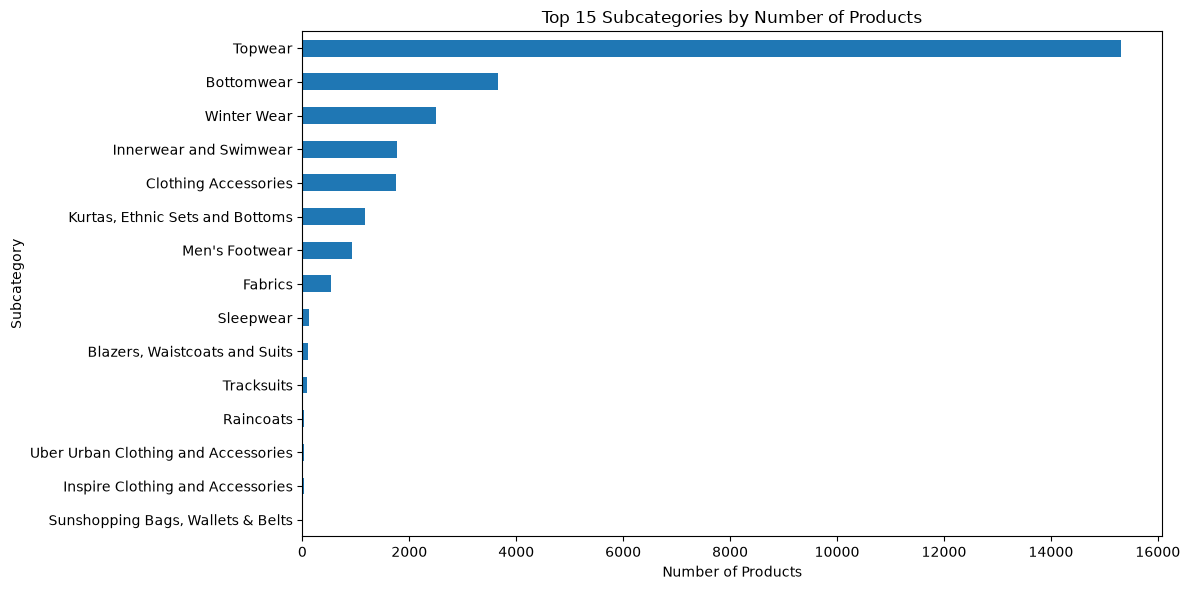

In [20]:
subcategory_counts = df["sub_category"].value_counts()

print("Number of subcategories:", df["sub_category"].nunique())
print("Top 15 subcategories:")
print(subcategory_counts.head(15))

plt.figure(figsize=(12, 6))

subcategory_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Subcategories by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()


The dataset contains 24 subcategories, with an uneven distribution. Topwear contains the most products, 15310, followed by Bottomwear and Winter Wear.

The top 5 subcategories are more or les the 90% of the products, while several subcategories contain very few items.

This imbalance may influence the retrieval system since queries related to common product types will have a much larger number of candidate documents than queries targeting less represented subcategories.

Brand distribution

Number of brands: 325

Top 15 brands:
brand
                2009
ECKO Unl         951
Free Authori     860
ARBO             806
REEB             802
Pu               798
True Bl          793
Keo              660
Amp              585
Black Beat       548
vims rai         503
yellowvib        492
PixF             429
Oka              414
Gracew           405
Name: count, dtype: int64


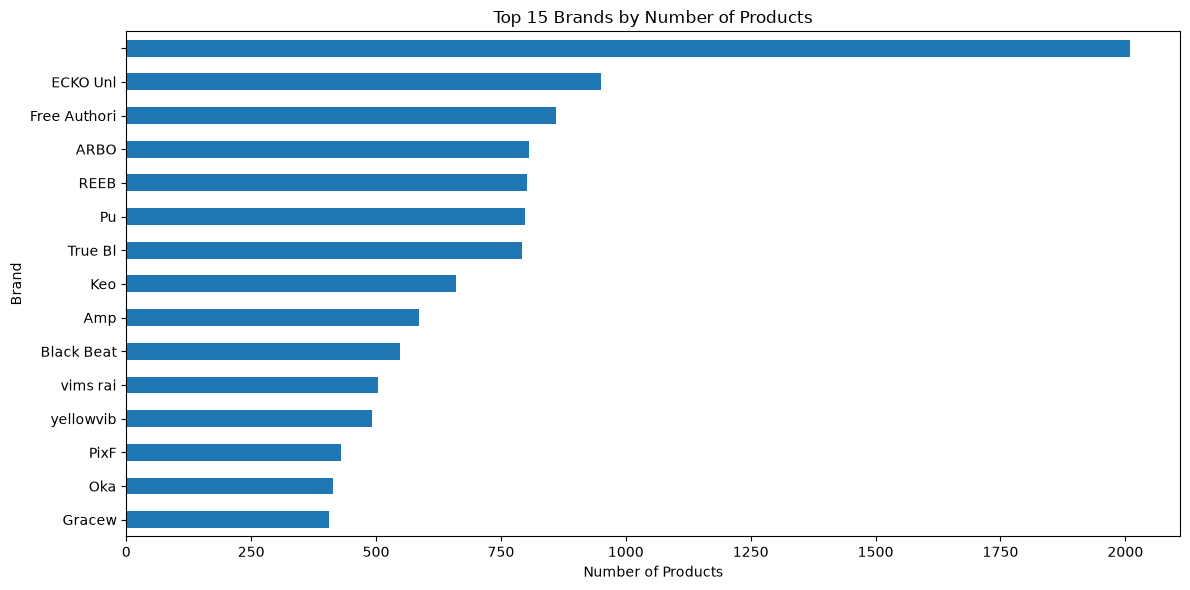

In [21]:
brand_counts = df["brand"].value_counts()

print("Number of brands:", df["brand"].nunique())
print("\nTop 15 brands:")
print(brand_counts.head(15))

plt.figure(figsize=(12, 6))

brand_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Brands by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()






The dataset contains 325 brand values, including an empty brand label. A total of 2009 products have no brand information, despite not being represented as null values.

Among products with an identified brand, ECKO Unl is the most frequent (951 products), followed by Free Authori (860), ARBO (806), and REEB (802).

Some brand names also appear to be truncated or incomplete. These data quality issues are relevant for information retrieval because missing or inconsistent brand names may reduce the effectiveness of specific searches of brands.

Seller distribution

Number of distinct seller labels: 535
Products with unknown seller: 1643

Top 15 sellers:
seller
Unknown seller           1643
RetailNet                1411
SandSMarketing            887
BioworldMerchandising     842
ARBOR                     783
Keoti                     660
AFFGARMENTS               587
Black Beatle              548
AMALGUS ENTERPRISE        477
Tayab Manch Fashions      436
KAPSONSRETAILPVTLTD       415
GRACEWAY                  408
T-SHIRT EXPRESS           393
OKANE                     386
WHITE SKY                 371
Name: count, dtype: int64


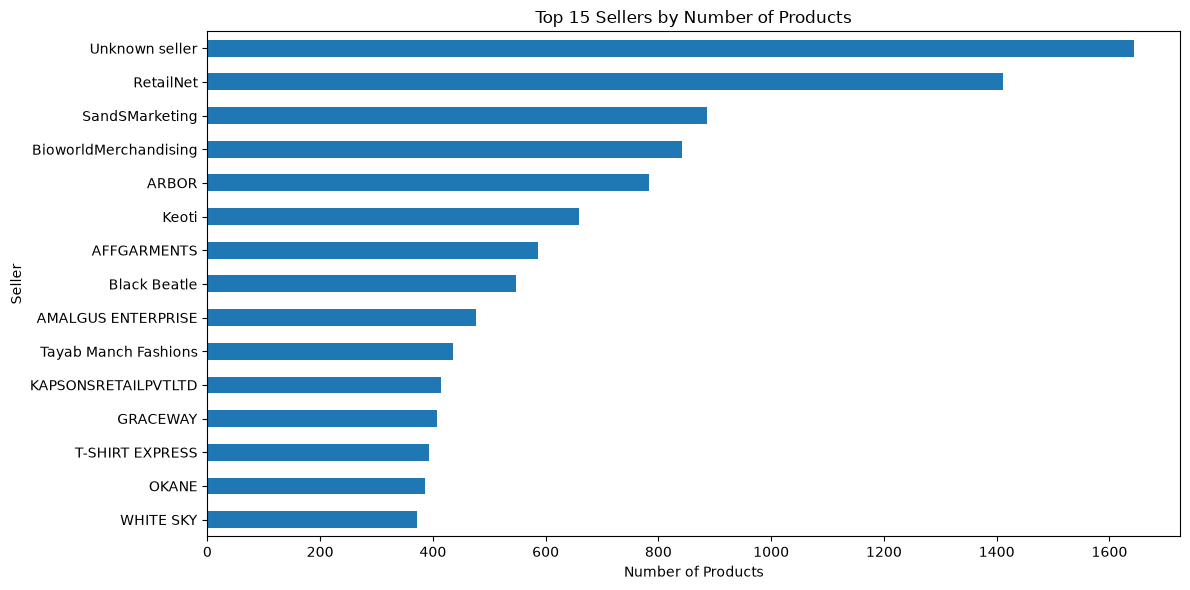

In [22]:
seller_labels = df["seller"].fillna("").str.strip()
seller_labels = seller_labels.replace("", "Unknown seller")

seller_counts = seller_labels.value_counts()

print("Number of distinct seller labels:", seller_counts.size)
print("Products with unknown seller:",
      (seller_labels == "Unknown seller").sum())

print("\nTop 15 sellers:")
print(seller_counts.head(15))

plt.figure(figsize=(12, 6))

seller_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Sellers by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Seller")
plt.tight_layout()
plt.show()


The dataset contains 535 seller labels, including empties values. 1643 products have no seller information.

RetailNet has the largest number of products (1,411), followed by SandSMarketing (887), BioworldMerchandising (842), and ARBOR (783).

The distribution is uneven, with some sellers contributing substantially more products than others. Missing seller information may also limit the filtering of sellers and retrievals.

**Text Analysis**

Word count distribution

Average title length (original): 6.46
Average title length (processed): 6.27
Average description length (original): 29.77
Average description length (processed): 18.84
Products with no description terms: 11150


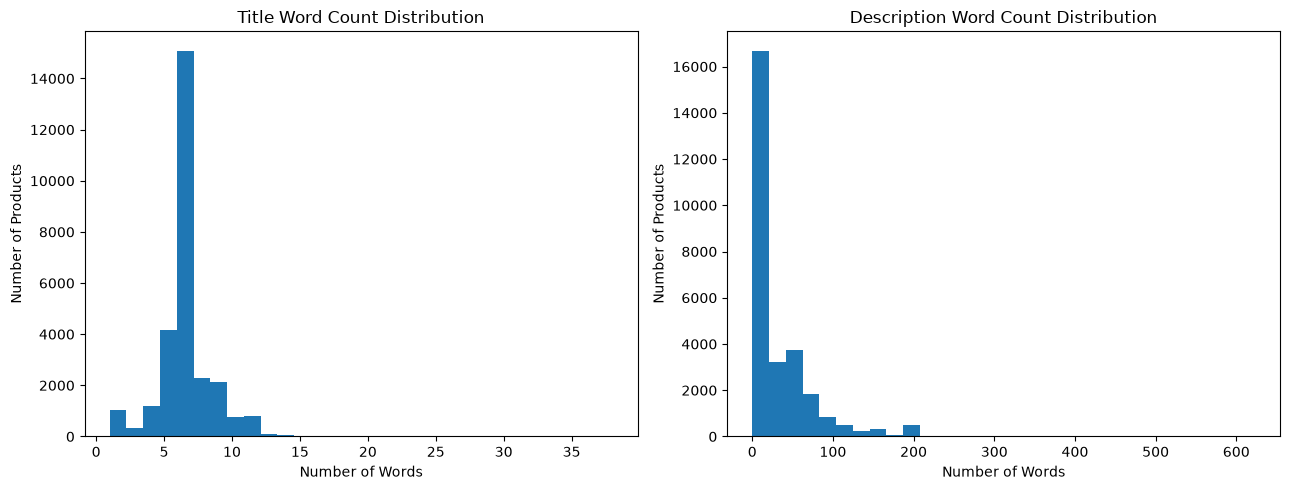

In [23]:
title_word_counts = df["title"].fillna("").str.split().str.len() #we replace the nulls by empty strings, split the strings into words and count the number of words in each title
description_word_counts = df["description"].fillna("").str.split().str.len() #we replace the nulls by empty strings, split the strings into words and count the number of words in each description

title_term_counts = df["title_terms"].apply(len) #we count the number of terms in each title after preprocessing
description_term_counts = df["description_terms"].apply(len) #we count the number of terms in each description after preprocessing

print("Average title length (original):", round(title_word_counts.mean(), 2))
print("Average title length (processed):", round(title_term_counts.mean(), 2))

print("Average description length (original):", round(description_word_counts.mean(), 2))
print("Average description length (processed):", round(description_term_counts.mean(), 2))

print("Products with no description terms:", (description_term_counts == 0).sum()) #number of products with no description terms after preprocessing

#visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(title_word_counts, bins=30)
axes[0].set_title("Title Word Count Distribution")
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Number of Products")

axes[1].hist(description_word_counts, bins=30)
axes[1].set_title("Description Word Count Distribution")
axes[1].set_xlabel("Number of Words")
axes[1].set_ylabel("Number of Products")

plt.tight_layout()
plt.show()


Product titles contain an average of 6.46 words, while descriptions contain 29.77. After preprocessing, these averages decrease to 6.27 and 18.84 terms, respectively.

Additionally, lots of products have empty descriptions. This highlights the importance of using titles and other product attributes for indexing and retrieval.

Vocabulary sizes

In [24]:
title_vocabulary = set() #dictionary for the vocabulary of the titles
description_vocabulary = set() #dictionary for the vocabulary of the descriptions

for terms in df["title_terms"]: #we iterate over all the terms in the title_terms column of the dataframe and we add them to the title_vocabulary set
    title_vocabulary.update(terms)

for terms in df["description_terms"]: #we iterate over all the terms in the description_terms column of the dataframe and we add them to the description_vocabulary set
    description_vocabulary.update(terms)

combined_vocabulary = title_vocabulary.union(description_vocabulary) #we combine the two vocabularies into one

print("Title vocabulary size:", len(title_vocabulary))
print("Description vocabulary size:", len(description_vocabulary))
print("Combined vocabulary size:", len(combined_vocabulary))


Title vocabulary size: 738
Description vocabulary size: 4698
Combined vocabulary size: 4902


After preprocessing, the combined vocabulary contains 4,902 unique terms. Description provides more vocabulary than title with 4698 vs 738 terms. Both fields can be useful for indexing.

Most frequent words

Top 20 most frequent terms:
[('shirt', 18321), ('cotton', 10139), ('wear', 9353), ('comfort', 8836), ('look', 6413), ('casual', 6034), ('fit', 5831), ('made', 5643), ('fabric', 5516), ('print', 4888), ('women', 4424), ('design', 4301), ('sleev', 4221), ('qualiti', 4087), ('men', 3775), ('wash', 3731), ('day', 3617), ('style', 3275), ('make', 3233), ('100', 3210)]


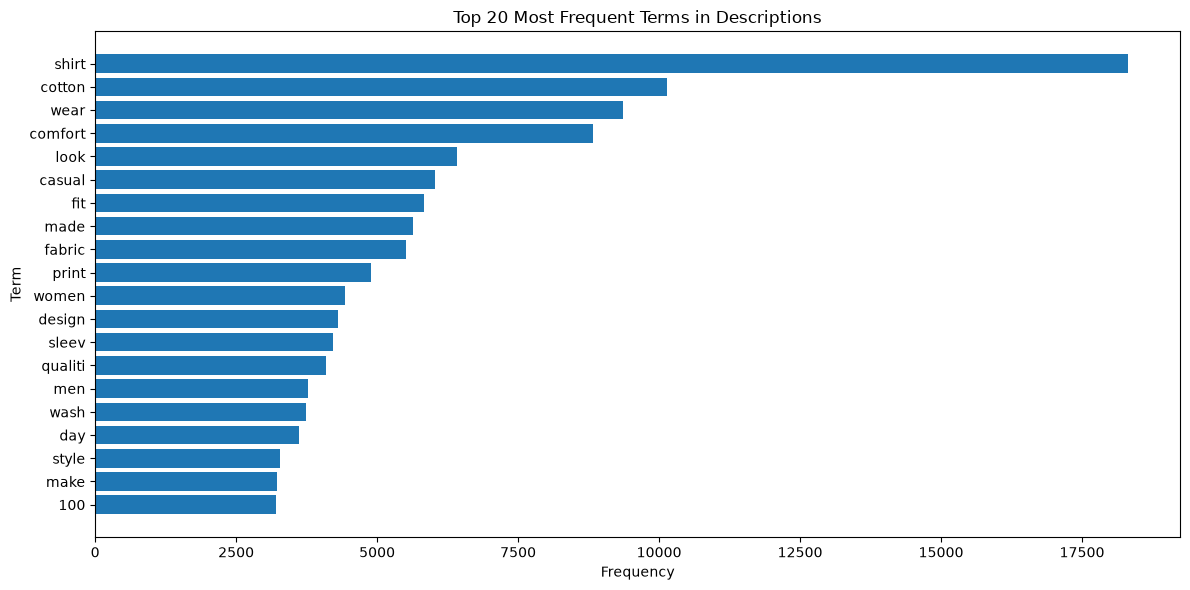

In [25]:
term_counts = Counter(t for terms in df["description_terms"] for t in terms) #we count the frequency of each term in the description_terms column of the dataframe using a Counter object

top_terms = term_counts.most_common(20) #top 20 most frequent terms in the descriptions

print("Top 20 most frequent terms:")
print(top_terms)

#plot
plt.figure(figsize=(12, 6))
plt.barh(
    [term for term, count in top_terms][::-1],
    [count for term, count in top_terms][::-1]
)

plt.title("Top 20 Most Frequent Terms in Descriptions")
plt.xlabel("Frequency")
plt.ylabel("Term")
plt.tight_layout()
plt.show()



The most frequent terms are related to clothing and product characteristics, like shirt, cotton, wear, and comfort. This make sense since the dataset is focused on clothing. Some terms appear shortened due to stemming.

**Price, Discount and Rating anlysis**

Price analysis

Selling price statistics:
count     28080
unique     1512
top         399
freq       1500
Name: selling_price, dtype: object
Products with zero price: 0


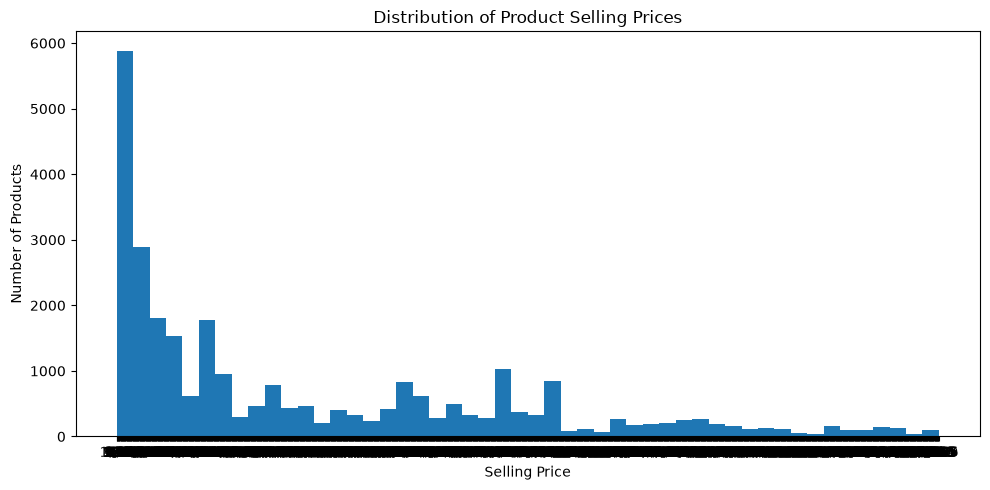

In [26]:
print("Selling price statistics:")
print(df["selling_price"].describe())

print("Products with zero price:", (df["selling_price"] == 0).sum())

plt.figure(figsize=(10, 5))
plt.hist(df["selling_price"].dropna(), bins=50)

plt.title("Distribution of Product Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


Selling prices have a median of 545 and a mean of 705.64, indicating a right-skewed distribution with some expensive products, as we can also see in the plot. Most prices are concentrated in lower ranges, while two products have missing price values.

Discount analysis

Discount statistics:
count       28080
unique         88
top       50% off
freq         2080
Name: discount, dtype: object

Products with zero discount: 0


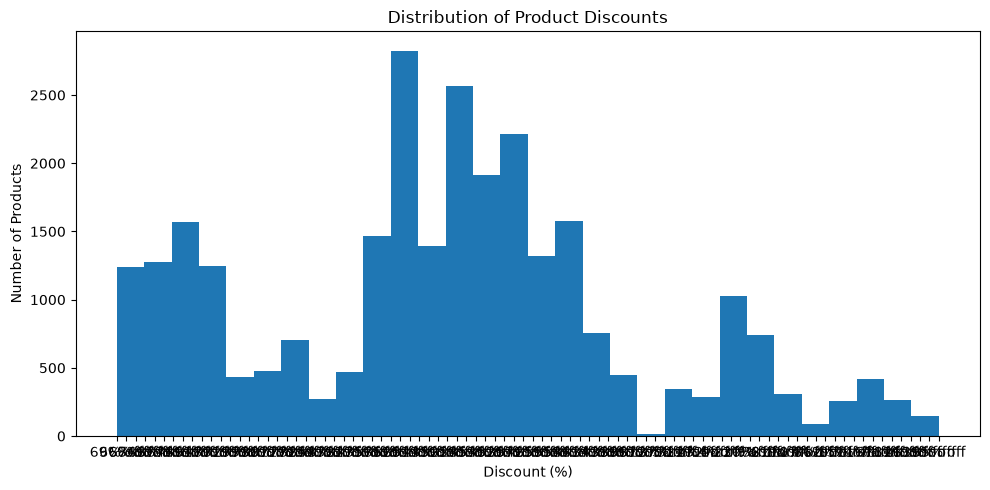

In [27]:
print("Discount statistics:")
print(df["discount"].describe())

print("\nProducts with zero discount:", (df["discount"] == 0).sum())

plt.figure(figsize=(10, 5))
plt.hist(df["discount"].dropna(), bins=30)

plt.title("Distribution of Product Discounts")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


Product discounts are generally high, with an average of 50.26% and a median of 53%. Most discounts are concentrated between 40% and 65%, while 855 products have missing discount values.

Rating analysis

Rating statistics:
count     28080
unique       39
top         3.9
freq       2605
Name: average_rating, dtype: object
Products with zero rating: 0


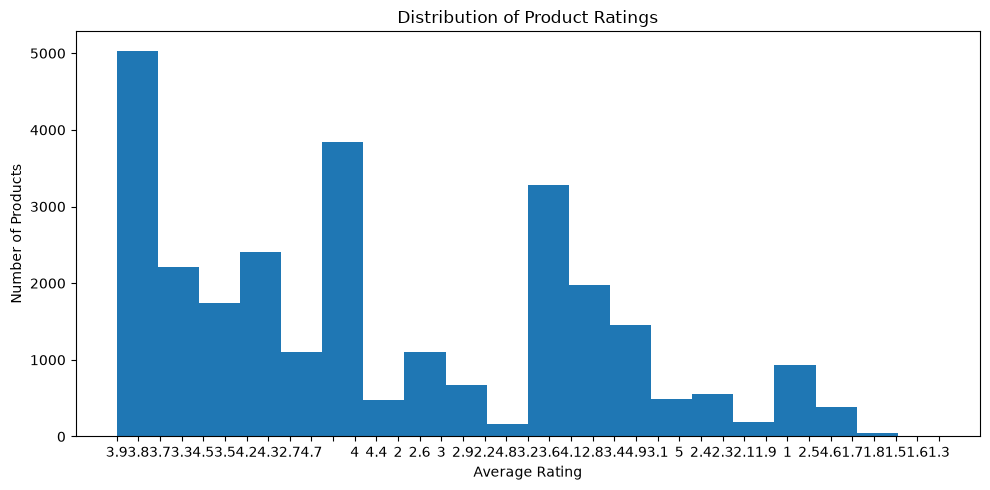

In [28]:
print("Rating statistics:")
print(df["average_rating"].describe())

print("Products with zero rating:", (df["average_rating"] == 0).sum())

plt.figure(figsize=(10, 5))
plt.hist(df["average_rating"].dropna(), bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


Product ratings are generally positive, with an average of 3.63 and a median of 3.8. Most ratings are concentrated between 3 and 4.5, while 2,261 products have missing rating values.

**Product rankings**

Top rated products

In [29]:
top_rated = df.sort_values(by="average_rating",ascending=False).head(10) #we sort the dataframe by average_rating in descending order and select the top 10 products

display(top_rated[["title", "brand", "average_rating", "selling_price"]])


,title,brand,average_rating,selling_price
5954,Women Regular Fit Solid Button Down Collar For...,MILD,5,563
17399,Women Regular Fit Solid Spread Collar Collar F...,Rose We,5,399
4220,Women Slim Fit Solid Casual Shirt,FOREVER YOU,5,725
17542,Women Solid Mid-Calf/Crew (Pack of 10),Cots,5,475
23909,Printed Men Round Neck Red T-Shirt,Free Authori,5,519
23906,Printed Men Round Neck Yellow T-Shirt,Free Authori,5,454
11309,Full Sleeve Solid Women Jacket,ECKO Unl,5,"1,874"
4354,Solid Men Polo Neck Multicolor T-Shirt (Pack ...,Shoef,5,616
4357,Solid Men Polo Neck Multicolor T-Shirt (Pack ...,Shoef,5,806
23852,Graphic Print Men Round Neck Blue T-Shirt,Free Authori,5,519


The top 10 rated products all have a rating of 5.0. We can see that the prices differ between them. However, since the number of reviews is unavailable, these ratings alone cannot determine product popularity or reliability.

Most expensive products

In [30]:
most_expensive = df.sort_values(by="selling_price",ascending=False).head(10) #get the top ten most expensive products by sorting the dataframe by selling_price in descending order and selecting the first 10 rows

display(most_expensive[["title", "brand", "selling_price", "average_rating"]])


,title,brand,selling_price,average_rating
22795,Women Regular Fit Solid Slim Collar Casual Shirt,A,999,2.8
22770,Women Regular Fit Solid Spread Collar Casual S...,A,999,2.8
22768,Men Regular Fit Washed Mandarin Collar Casual ...,A,999,2.8
22767,Women Regular Fit Washed Mandarin Collar Casua...,A,999,2.8
22766,Men Regular Fit Self Design Button Down Collar...,A,999,2.8
22765,Men Regular Fit Washed Spread Collar Casual Shirt,A,999,2.8
22763,Women Regular Fit Solid Spread Collar Casual S...,A,999,2.8
22762,Men Regular Fit Washed Spread Collar Casual Shirt,A,999,2.8
22761,Men Regular Fit Washed Mandarin Collar Casual ...,A,999,2.8
22760,Men Regular Fit Washed Slim Collar Casual Shirt,A,999,2.8


The most expensive products have selling prices between 6,493 and 7,999. Their ratings differ considerably, suggesting that higher prices do not necessarily correspond to better customer evaluations.

Products with the highest discounts

In [31]:
highest_discounts = df.sort_values(by="discount",ascending=False).head(10) #we sort the values by the column discount and ordering them in a descending way

display(highest_discounts[["title", "brand", "discount", "selling_price"]])


,title,brand,discount,selling_price
3740,"Maxter Badminton Shoes For Women (Blue, Green)",Vector,9% off,"1,170"
3606,"VX-7.0 Running Shoes For Men (Maroon, Black)",Vector,9% off,675
3648,"IGNITE Football Shoes For Men (Yellow, Purple)",Vector,9% off,"1,598"
3646,Walking Shoes For Men (Navy),Vector,9% off,810
3644,"Football Shoes For Men (Silver, Blue)",Vector,9% off,945
3641,"Basketball Shoes For Men (Green, Black)",Vector,9% off,"1,440"
3639,"FLYER Football Shoes For Women (Green, Black)",Vector,9% off,"1,710"
3638,"IMPULSE Football Shoes For Women (Green, Blue)",Vector,9% off,900
3635,Sports Shoes For Women (Multicolor),Vector,9% off,450
3634,"ACURA+ Football Shoes For Women (Black, Green)",Vector,9% off,653


The highest discounts range from 84% to 87%, and most of them is in T-shirts. These products generally have low selling prices, with Jack Roy and yellowvib appearing frequently among the most discounted items.

**Stock availabilities**

Stock distribution:
out_of_stock
False    26436
True      1644
Name: count, dtype: int64
Stock distribution (%):
out_of_stock
False    94.145299
True      5.854701
Name: proportion, dtype: float64


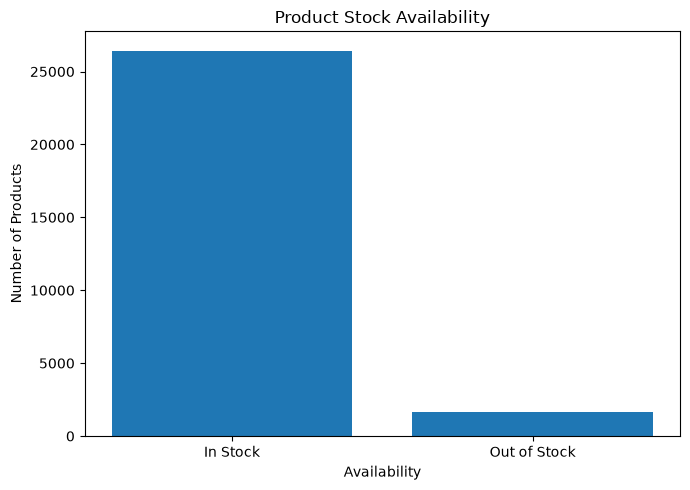

In [32]:
stock_counts = df["out_of_stock"].value_counts()

print("Stock distribution:")
print(stock_counts)

print("Stock distribution (%):")
print(df["out_of_stock"].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))
plt.bar(
    ["In Stock", "Out of Stock"],
    [
        (df["out_of_stock"] == False).sum(),
        (df["out_of_stock"] == True).sum()
    ]
)

plt.title("Product Stock Availability")
plt.xlabel("Availability")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


Most products are in stock (94.15%), while only 5.85% are out of stock. Stock availability could be used as a filtering criterion in the search engine.